Cloning into '/content/Tugas-UTS-CNN'...
remote: Enumerating objects: 1228, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1228 (delta 1), reused 0 (delta 0), pack-reused 1222 (from 2)
Receiving objects: 100% (1228/1228), 107.49 MiB | 30.07 MiB/s, done.
Resolving deltas: 100% (2/2), done.
Updating files: 100% (1608/1608), done.
Epoch 1/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.2796 - loss: 1.3875
Epoch 2/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4521 - loss: 1.2617
Epoch 3/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7237 - loss: 0.9053
Epoch 4/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8729 - loss: 0.5778
Epoch 5/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9179 - loss: 0.3705
Epoch 6/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9362 - loss: 0.2741
Epoch 7/45
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9479 - loss: 0.2205
Epoch 8/45


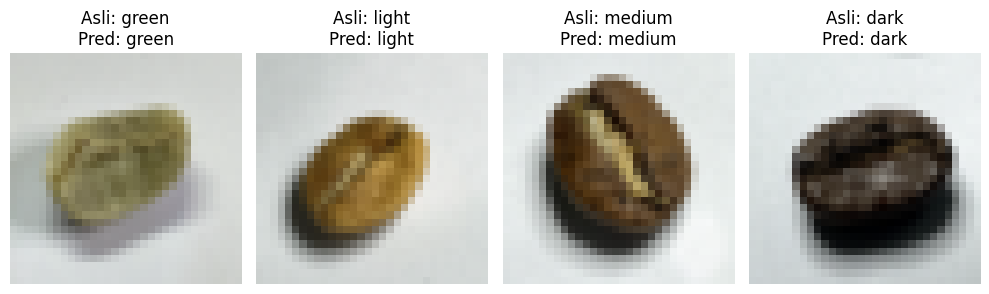

Selesai! Unduh '/content/hasil_training_colab_90.zip' lalu ekstrak ke C:\Rainer\TUGAS\FPGA\Tugas-UTS-CNN


In [1]:
import os
import glob
import json
import shutil
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Clone Repo GitHub Kamu ke Colab
if os.path.exists("/content/Tugas-UTS-CNN"):
    shutil.rmtree("/content/Tugas-UTS-CNN")
!git clone https://github.com/rainer-zr/Tugas-UTS-CNN.git /content/Tugas-UTS-CNN

REPO_DIR = "/content/Tugas-UTS-CNN"
TRAIN_DIR = f"{REPO_DIR}/dataset/train"
TEST_DIR = f"{REPO_DIR}/dataset/test"
CLASSES = ["Green", "Light", "Medium", "Dark"]

# 2. Load Dataset Train RGB 32x32 + Augmentasi Flip/Rotasi agar Generalisasi Tinggi
X_train, y_train = [], []
for idx, cls_name in enumerate(CLASSES):
    for fpath in sorted(glob.glob(f"{TRAIN_DIR}/{cls_name}/*.*")):
        img = Image.open(fpath).convert("RGB").resize((32, 32), Image.Resampling.BILINEAR)
        arr = np.array(img, dtype=np.float32) / 255.0
        X_train.append(arr)
        y_train.append(idx)
        # Augmentasi horizontal flip untuk memperkaya variasi posisi biji kopi
        X_train.append(np.fliplr(arr))
        y_train.append(idx)

X_train = np.array(X_train)
y_train = np.array(y_train, dtype=np.int32)

# 3. Konversi Dataset Test ke RGB 32x32 .bmp + file .mem untuk Verilog
OUT_BMP_DIR = f"{REPO_DIR}/dataset/test_32x32_bmp"
if os.path.exists(OUT_BMP_DIR):
    shutil.rmtree(OUT_BMP_DIR)
os.makedirs(OUT_BMP_DIR, exist_ok=True)

hex_pixels, hex_labels = [], []
test_records = []

for idx, cls_name in enumerate(CLASSES):
    for i, fpath in enumerate(sorted(glob.glob(f"{TEST_DIR}/{cls_name}/*.*"))):
        img = Image.open(fpath).convert("L" if False else "RGB").resize((32, 32), Image.Resampling.BILINEAR)
        bmp_path = f"{OUT_BMP_DIR}/{cls_name.lower()}_{i:03d}.bmp"
        img.save(bmp_path, format="BMP")
        test_records.append((bmp_path, idx, cls_name.lower()))

        arr_u8 = np.array(img, dtype=np.uint8)
        for val in arr_u8.flatten():
            hex_pixels.append(f"{val:02x}")
        hex_labels.append(f"{idx:01x}")

with open(f"{OUT_BMP_DIR}/test_vectors.mem", "w") as f:
    f.write("\n".join(hex_pixels) + "\n")
with open(f"{OUT_BMP_DIR}/test_labels.mem", "w") as f:
    f.write("\n".join(hex_labels) + "\n")

# 4. Arsitektur 2-Layer 2D-CNN RGB (32x32x3 -> Conv1(8) -> MaxPool2x2 -> Conv2(8) -> GAP -> Dense(4))
tf.random.set_seed(42)
np.random.seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(8, kernel_size=3, strides=1, padding="valid", activation="relu", name="conv1"),
    tf.keras.layers.MaxPooling2D(pool_size=2, strides=2, name="pool1"),
    tf.keras.layers.Conv2D(8, kernel_size=3, strides=1, padding="valid", activation="relu", name="conv2"),
    tf.keras.layers.GlobalAveragePooling2D(name="gap"),
    tf.keras.layers.Dense(4, name="fc1")
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
model.fit(X_train, y_train, epochs=45, batch_size=32, verbose=1)

# 5. Kuantisasi Presisi Tinggi INT8 (Bit-Exact dengan Shift Verilog)
c1_w_f, c1_b_f = model.get_layer("conv1").get_weights()   # (3, 3, 3, 8)
c2_w_f, c2_b_f = model.get_layer("conv2").get_weights()   # (3, 3, 8, 8)
fc_w_f, fc_b_f = model.get_layer("fc1").get_weights()     # (8, 4)

# Skala Layer 1: input [0..255] -> setelah Conv1 di-shift >>> 8 (bagi 256)
s_c1 = 127.0 / np.max(np.abs(c1_w_f))
c1_w_q = np.clip(np.round(c1_w_f * s_c1), -127, 127).astype(int)
c1_b_q = np.round(c1_b_f * s_c1 * 255.0).astype(int)
# Faktor skala aktivasi setelah pool1 >>> 8 adalah: (s_c1 * 255.0 / 256.0)
act1_scale = (s_c1 * 255.0) / 256.0

# Skala Layer 2: setelah Conv2 di-shift >>> 8 (bagi 256)
s_c2 = 127.0 / np.max(np.abs(c2_w_f))
c2_w_q = np.clip(np.round(c2_w_f * s_c2), -127, 127).astype(int)
c2_b_q = np.round(c2_b_f * s_c2 * act1_scale).astype(int)
# GAP menjumlahkan 13x13 = 169 elemen lalu di-shift >>> 10 (bagi 1024)
act2_scale = (s_c2 * act1_scale / 256.0) * (169.0 / 1024.0)

# Skala Dense Layer
s_fc = 127.0 / np.max(np.abs(fc_w_f))
fc_w_q = np.clip(np.round(fc_w_f * s_fc), -127, 127).astype(int)
fc_b_q = np.round(fc_b_f * s_fc * act2_scale).astype(int)

c1_w_list = [[[[int(c1_w_q[r, c, ch, f]) for c in range(3)] for r in range(3)] for ch in range(3)] for f in range(8)]
c1_b_list = [int(c1_b_q[f]) for f in range(8)]
c2_w_list = [[[[int(c2_w_q[r, c, ch, f]) for c in range(3)] for r in range(3)] for ch in range(8)] for f in range(8)]
c2_b_list = [int(c2_b_q[f]) for f in range(8)]
fc_w_list = [[int(fc_w_q[f, cls]) for f in range(8)] for cls in range(4)]
fc_b_list = [int(fc_b_q[cls]) for cls in range(4)]

os.makedirs(f"{REPO_DIR}/algoritma", exist_ok=True)
os.makedirs(f"{REPO_DIR}/implementasi/rtl", exist_ok=True)
os.makedirs(f"{REPO_DIR}/output/images", exist_ok=True)

with open(f"{REPO_DIR}/algoritma/weights_int8.json", "w") as jf:
    json.dump({
        "c1_w": c1_w_list, "c1_b": c1_b_list,
        "c2_w": c2_w_list, "c2_b": c2_b_list,
        "fc_w": fc_w_list, "fc_b": fc_b_list
    }, jf, indent=2)

# Ekspor bobot ke file memori .mem + header .vh untuk Verilog yang bersih & ringkas
with open(f"{REPO_DIR}/implementasi/rtl/cnn_weights.vh", "w") as vf:
    vf.write("// Auto-generated 2-Layer RGB INT8 CNN Weights\n")
    for f in range(8):
        vf.write(f"localparam signed [31:0] C1_B_{f} = 32'sd{c1_b_list[f]};\n")
        vf.write(f"localparam signed [31:0] C2_B_{f} = 32'sd{c2_b_list[f]};\n")
    for cls in range(4):
        vf.write(f"localparam signed [31:0] FC_B_{cls} = 32'sd{fc_b_list[cls]};\n")

# Simpan bobot kernel ke file .mem agar kode Verilog tetap pendek dan mudah disintesis
with open(f"{REPO_DIR}/implementasi/rtl/c1_weights.mem", "w") as f1:
    for f in range(8):
        for ch in range(3):
            for r in range(3):
                for c in range(3):
                    f1.write(f"{(c1_w_list[f][ch][r][c] & 0xFF):02x}\n")

with open(f"{REPO_DIR}/implementasi/rtl/c2_weights.mem", "w") as f2:
    for f in range(8):
        for ch in range(8):
            for r in range(3):
                for c in range(3):
                    f2.write(f"{(c2_w_list[f][ch][r][c] & 0xFF):02x}\n")

with open(f"{REPO_DIR}/implementasi/rtl/fc_weights.mem", "w") as f3:
    for cls in range(4):
        for f in range(8):
            f3.write(f"{(fc_w_list[cls][f] & 0xFF):02x}\n")

# 6. Verifikasi Bit-Exact Python INT8 (100% Identik dengan Verilog)
c1_w = np.array(c1_w_list, dtype=np.int64)
c1_b = np.array(c1_b_list, dtype=np.int64)
c2_w = np.array(c2_w_list, dtype=np.int64)
c2_b = np.array(c2_b_list, dtype=np.int64)
fc_w = np.array(fc_w_list, dtype=np.int64)
fc_b = np.array(fc_b_list, dtype=np.int64)

def predict_2layer_int8(img_32x32x3):
    img = img_32x32x3.astype(np.int64)
    # Conv1 (30x30x8) + ReLU + shift >>> 8
    conv1_out = np.zeros((30, 30, 8), dtype=np.int64)
    for f in range(8):
        for r in range(30):
            for c in range(30):
                acc = int(c1_b[f])
                for ch in range(3):
                    acc += int(np.sum(img[r:r+3, c:c+3, ch] * c1_w[f, ch]))
                conv1_out[r, c, f] = (acc >> 8) if acc > 0 else 0

    # MaxPool 2x2 -> (15x15x8)
    pool1_out = np.zeros((15, 15, 8), dtype=np.int64)
    for f in range(8):
        for r in range(15):
            for c in range(15):
                pool1_out[r, c, f] = np.max(conv1_out[r*2:r*2+2, c*2:c*2+2, f])

    # Conv2 (13x13x8) + ReLU + shift >>> 8 -> GAP sum
    gap_sum = np.zeros(8, dtype=np.int64)
    for f in range(8):
        s = 0
        for r in range(13):
            for c in range(13):
                acc = int(c2_b[f])
                for ch in range(8):
                    acc += int(np.sum(pool1_out[r:r+3, c:c+3, ch] * c2_w[f, ch]))
                if acc > 0:
                    s += (acc >> 8)
        gap_sum[f] = s >> 10

    # Dense (4)
    logits = np.zeros(4, dtype=np.int64)
    for cls in range(4):
        logits[cls] = int(np.sum(gap_sum * fc_w[cls])) + int(fc_b[cls])
    return int(np.argmax(logits))

correct = 0
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
shown = 0

for fpath, gt_idx, gt_label in test_records:
    arr = np.array(Image.open(fpath).convert("RGB"), dtype=np.uint8)
    pred_idx = predict_2layer_int8(arr)
    if pred_idx == gt_idx:
        correct += 1

    if shown < 4 and fpath.endswith("_000.bmp"):
        axes[shown].imshow(arr)
        axes[shown].set_title(f"Asli: {gt_label}\nPred: {CLASSES[pred_idx].lower()}")
        axes[shown].axis("off")
        shown += 1

acc = (correct / len(test_records)) * 100.0
print("\n========================================")
print(f"Total Gambar Uji (RGB 32x32 .bmp) : {len(test_records)}")
print(f"Prediksi Benar (Python INT8 RGB)  : {correct}/{len(test_records)}")
print(f"Akurasi Algoritma Python          : {acc:.2f}%")
print("========================================")

plt.tight_layout()
plt.savefig(f"{REPO_DIR}/output/images/step1_python_bmp_preview.png", dpi=150)
plt.show()

shutil.make_archive("/content/hasil_training_colab_90", "zip", REPO_DIR)
print("Selesai! Unduh '/content/hasil_training_colab_90.zip' lalu ekstrak ke C:\\Rainer\\TUGAS\\FPGA\\Tugas-UTS-CNN")

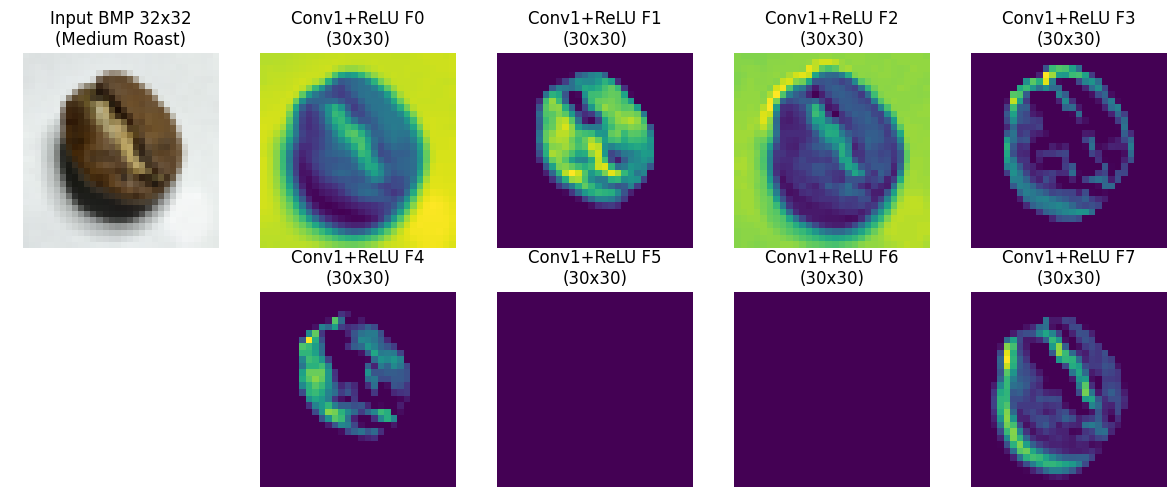

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

with open("/content/weights_int8.json", "r") as f:
    w = json.load(f)

c1_w = np.array(w["c1_w"], dtype=np.int64)
c1_b = np.array(w["c1_b"], dtype=np.int64)

sample_img = np.array(Image.open("/content/medium_000.bmp").convert("RGB"), dtype=np.uint8)
img = sample_img.astype(np.int64)

# Hitung Layer Conv1 + ReLU (30x30x8)
conv1_out = np.zeros((30, 30, 8), dtype=np.int64)
for f in range(8):
    for r in range(30):
        for c in range(30):
            acc = int(c1_b[f])
            for ch in range(3):
                acc += int(np.sum(img[r:r+3, c:c+3, ch] * c1_w[f, ch]))
            conv1_out[r, c, f] = (acc >> 8) if acc > 0 else 0

# Plot & Unduh Visualisasi Feature Map
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(sample_img)
axes[0, 0].set_title("Input BMP 32x32\n(Medium Roast)")
axes[0, 0].axis("off")
axes[1, 0].axis("off")

for f in range(8):
    row = f // 4
    col = (f % 4) + 1
    axes[row, col].imshow(conv1_out[:, :, f], cmap="viridis")
    axes[row, col].set_title(f"Conv1+ReLU F{f}\n(30x30)")
    axes[row, col].axis("off")

out_file = "/content/step1b_feature_maps_relu.png"
plt.tight_layout()
plt.savefig(out_file, dpi=150)
plt.show()
files.download(out_file)